In [14]:
import dipole
import minimizing
import numpy as np
import matplotlib.pyplot as plt

In [19]:
bk_file = "../data/bk_samplefrommvefit.dat"
BKinterpolator = dipole.BKDipole(bk_file)
init = [1.0, 0.8, 1.0, 1.0]
lbounds = [0.001, 0.1, 0.1, 0.001]
ubounds = [10.0, 100.0, 100.0, 10.0]
#init = [(lbounds[i] + ubounds[i])/2 for i in range(len(lbounds))]
y = 2.0
r = np.logspace(-3, 2, 50)
Nyr = lambda yy,rr: BKinterpolator.ln_Nr(yy,rr) # Make interpolator to a callable function
minimizer = minimizing.MyMinimizer(Nyr, y, r, init, lbounds = lbounds, ubounds = ubounds)
out = minimizer.fit_ls()
fit_params = out.x
fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
print("Fitted parameters:", fit_params)

Fitted parameters: [0.08711199 2.0114968  0.35264388 0.48620888]


Text(0, 0.5, 'N(r,y)')

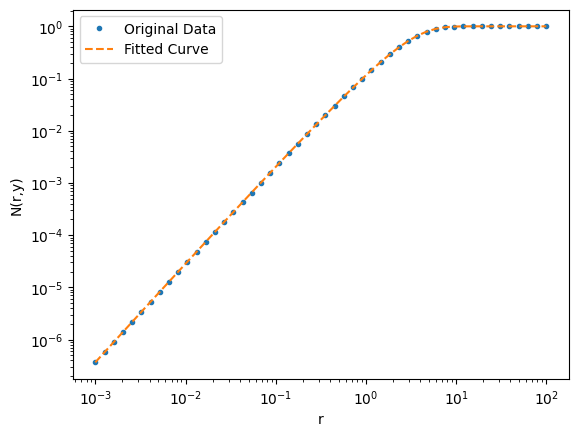

In [20]:
plt.plot(r, np.exp(Nyr(y,r)), '.', label='Original Data')
plt.plot(r, np.exp(fit_func), label='Fitted Curve', linestyle='--')
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.xlabel('r')
plt.ylabel('N(r,y)')


## Get Fourier transform

In [21]:
interpolator = BKinterpolator.ReadBKDipole()[0]
from hankel import HankelTransform

def S(k):

    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = interpolator(y, r) #minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

def S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

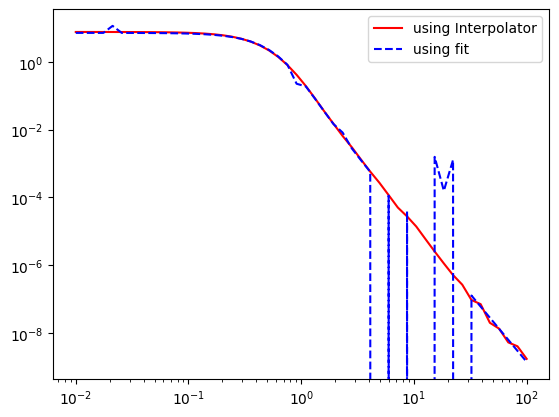

In [22]:
k = np.logspace(-2, 2, 50)
Sk = S(k)
Sk2 = S2(k, fit_params)
plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, Sk2, '--', label = 'using fit', color='blue')
plt.legend()
plt.xscale('log')
plt.yscale('log')